# ANALISIS DATA MINING FP-GROWTH — PT. SINAR SURYA MATAHARI (SSM MOTOR)
**Kerangka Kerja:** Cross-Industry Standard Process for Data Mining (CRISP-DM)  
**Tujuan Penelitian:** Multi-Attribute Association Rule Mining untuk Analisis Pola Transaksi, Preferensi Pembiayaan, dan Optimalisasi Persediaan  
**Dataset:** 3.113 Rekaman Transaksi Faktur Riil Yamaha Dealer Management System (Y-DMS)  
**Kelompok 1:** Darell Rangga Putra R. (4.1), Wahyu Rizky (4.2), Megi Refkiansyah (4.3), Bersama (4.4 & 4.5)

---


In [1]:
# ==========================================
# 0. IMPORT PUSTAKA UTAMA
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys

# Pustaka Association Rule Mining
from mlxtend.frequent_patterns import fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

# Konfigurasi Tampilan Grafik & Visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 300

# Deteksi path dataset secara dinamis
possible_dataset_paths = [
    os.path.join('..', 'datasets', '01_DATASET_UTAMA_DIGUNAKAN', 'data_transaksi_dealer_jun_agst_2026_clean.csv'),
    os.path.join('datasets', '01_DATASET_UTAMA_DIGUNAKAN', 'data_transaksi_dealer_jun_agst_2026_clean.csv'),
    r'D:\MATERI SLIDE\MATERI SMT 5\TUGAS SMT 5\Penelitian SI\datasets\01_DATASET_UTAMA_DIGUNAKAN\data_transaksi_dealer_jun_agst_2026_clean.csv'
]
data_path = next((p for p in possible_dataset_paths if os.path.exists(p)), possible_dataset_paths[0])
print(f"Dataset terdeteksi di: {data_path}")


Dataset terdeteksi di: ..\datasets\01_DATASET_UTAMA_DIGUNAKAN\data_transaksi_dealer_jun_agst_2026_clean.csv


---
## SUB-BAB 4.1: HASIL PEMAHAMAN DATA (DATA UNDERSTANDING) — TUGAS DARELL
Membuktikan keabsahan data empiris transaksi Y-DMS, skema metadata atribut, serta analisis univariat 5 dimensi.


In [2]:
# ==========================================
# 4.1.1 MEMUAT DATASET TRANSAKSI Y-DMS
# ==========================================
df_raw = pd.read_csv(data_path)

print(f"Total Baris Transaksi : {df_raw.shape[0]} baris")
print(f"Total Kolom Awal      : {df_raw.shape[1]} kolom")
print("\n5 Baris Pertama Data Mentah Y-DMS:")
display(df_raw.head())


Total Baris Transaksi : 3113 baris
Total Kolom Awal      : 12 kolom

5 Baris Pertama Data Mentah Y-DMS:
             TG_FAKTUR     NO_FAKTUR  ...  UMUR      NM_CABANG
0  2026-06-02T00:00:00  26FJK0101925  ...    17  GD.SSM BEKASI
1  2026-06-02T00:00:00  26FJK0101926  ...     5  GD.SSM BEKASI
2  2026-06-02T00:00:00  26FJK0101927  ...     5  GD.SSM BEKASI
3  2026-06-02T00:00:00  26FJK0101928  ...    28  GD.SSM BEKASI
4  2026-06-02T00:00:00  26FJK0101929  ...    14      SSM MOTOR

[5 rows x 12 columns]


In [3]:
# ==========================================
# 4.1.2 EKSPLORASI STATISTIK UNIVARIAT 5 DIMENSI
# ==========================================
print("=== 1. TOP 10 MODEL SEPEDA MOTOR (NAMA_BRG) ===")
s_model = df_raw['NAMA_BRG'].value_counts()
display(pd.DataFrame({'Frekuensi': s_model.head(10), 'Persentase (%)': (s_model.head(10)/len(df_raw)*100).round(2)}))

print("\n=== 2. TOP 10 VARIAN WARNA UNIT (WARNA) ===")
s_warna = df_raw['WARNA'].value_counts()
display(pd.DataFrame({'Frekuensi': s_warna.head(10), 'Persentase (%)': (s_warna.head(10)/len(df_raw)*100).round(2)}))

print("\n=== 3. LEMBAGA PEMBIAYAAN / SKEMA PEMBAYARAN ===")
def group_leasing(val):
    if pd.isna(val) or str(val).strip().upper() in ['CASH', 'TUNAI', 'NON LEASING', 'NAN']: return 'CASH'
    val = str(val).upper()
    if 'BAF' in val: return 'BAF'
    if 'ADIRA' in val or 'ADR' in val: return 'ADIRA'
    if 'OTO' in val: return 'OTO'
    if 'MUF' in val or 'MANDIRI' in val: return 'MANDIRI_UTAMA_FINANCE'
    if 'WOM' in val: return 'WOM'
    return 'LAINNYA'
s_lease = df_raw['NMLEASE'].apply(group_leasing).value_counts()
display(pd.DataFrame({'Frekuensi': s_lease, 'Persentase (%)': (s_lease/len(df_raw)*100).round(2)}))

print("\n=== 4. TENOR ANGSURAN PEMBIAYAAN ===")
def group_tenor(val):
    try: t = int(float(val))
    except: return '0_BULAN_CASH'
    if t == 0: return '0_BULAN_CASH'
    elif 1 <= t <= 17: return '11-17_BULAN'
    elif 18 <= t <= 23: return '20-23_BULAN'
    elif 24 <= t <= 32: return '30-32_BULAN'
    elif t >= 33: return '35_BULAN'
    return 'LAINNYA'
s_tenor = df_raw['JK_WAKTU'].apply(group_tenor).value_counts()
display(pd.DataFrame({'Frekuensi': s_tenor, 'Persentase (%)': (s_tenor/len(df_raw)*100).round(2)}))

print("\n=== 5. TOP 10 WILAYAH DOMISILI KONSUMEN ===")
def group_kota(val):
    if pd.isna(val): return 'WILAYAH_LAIN'
    val = str(val).upper().strip()
    if 'BEKASI' in val:
        if 'KAB' in val: return 'KABUPATEN_BEKASI'
        return 'KOTA_BEKASI'
    if 'JAKARTA TIMUR' in val: return 'JAKARTA_TIMUR'
    if 'JAKARTA SELATAN' in val: return 'JAKARTA_SELATAN'
    if 'JAKARTA BARAT' in val: return 'JAKARTA_BARAT'
    if 'JAKARTA PUSAT' in val: return 'JAKARTA_PUSAT'
    if 'JAKARTA UTARA' in val: return 'JAKARTA_UTARA'
    if 'JAKARTA' in val: return 'DKI_JAKARTA_LAIN'
    if 'DEPOK' in val: return 'KOTA_DEPOK'
    if 'BOGOR' in val: return 'BOGOR'
    if 'TANGERANG' in val: return 'TANGERANG'
    return 'WILAYAH_LAIN'
s_kota = df_raw['KOTA'].apply(group_kota).value_counts()
display(pd.DataFrame({'Frekuensi': s_kota.head(10), 'Persentase (%)': (s_kota.head(10)/len(df_raw)*100).round(2)}))


=== 1. TOP 10 MODEL SEPEDA MOTOR (NAMA_BRG) ===
                         Frekuensi  Persentase (%)
NAMA_BRG                                          
AEROX ALPHA                    468           15.03
MIO M3 CW                      434           13.94
GEAR 125                       325           10.44
NMAX NEO S                     252            8.10
GRAND FILANO HYBRID NEO        211            6.78
MX KING 150                    185            5.94
FAZZIO HYBRID NEO              142            4.56
FAZZIO HYBRID                  117            3.76
G ULTIMA HYBRID                110            3.53
G ULTIMA HYBRID SMART           96            3.08

=== 2. TOP 10 VARIAN WARNA UNIT (WARNA) ===
             Frekuensi  Persentase (%)
WARNA                                 
HITAM             1317           42.31
BIRU               349           11.21
MERAH              203            6.52
PUTIH              201            6.46
ABU-ABU            171            5.49
UNGU MUDA          138

Grafik 4.1 berhasil disimpan: visualisasi_4_1_univariat.png


<string>:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

<string>:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

<string>:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



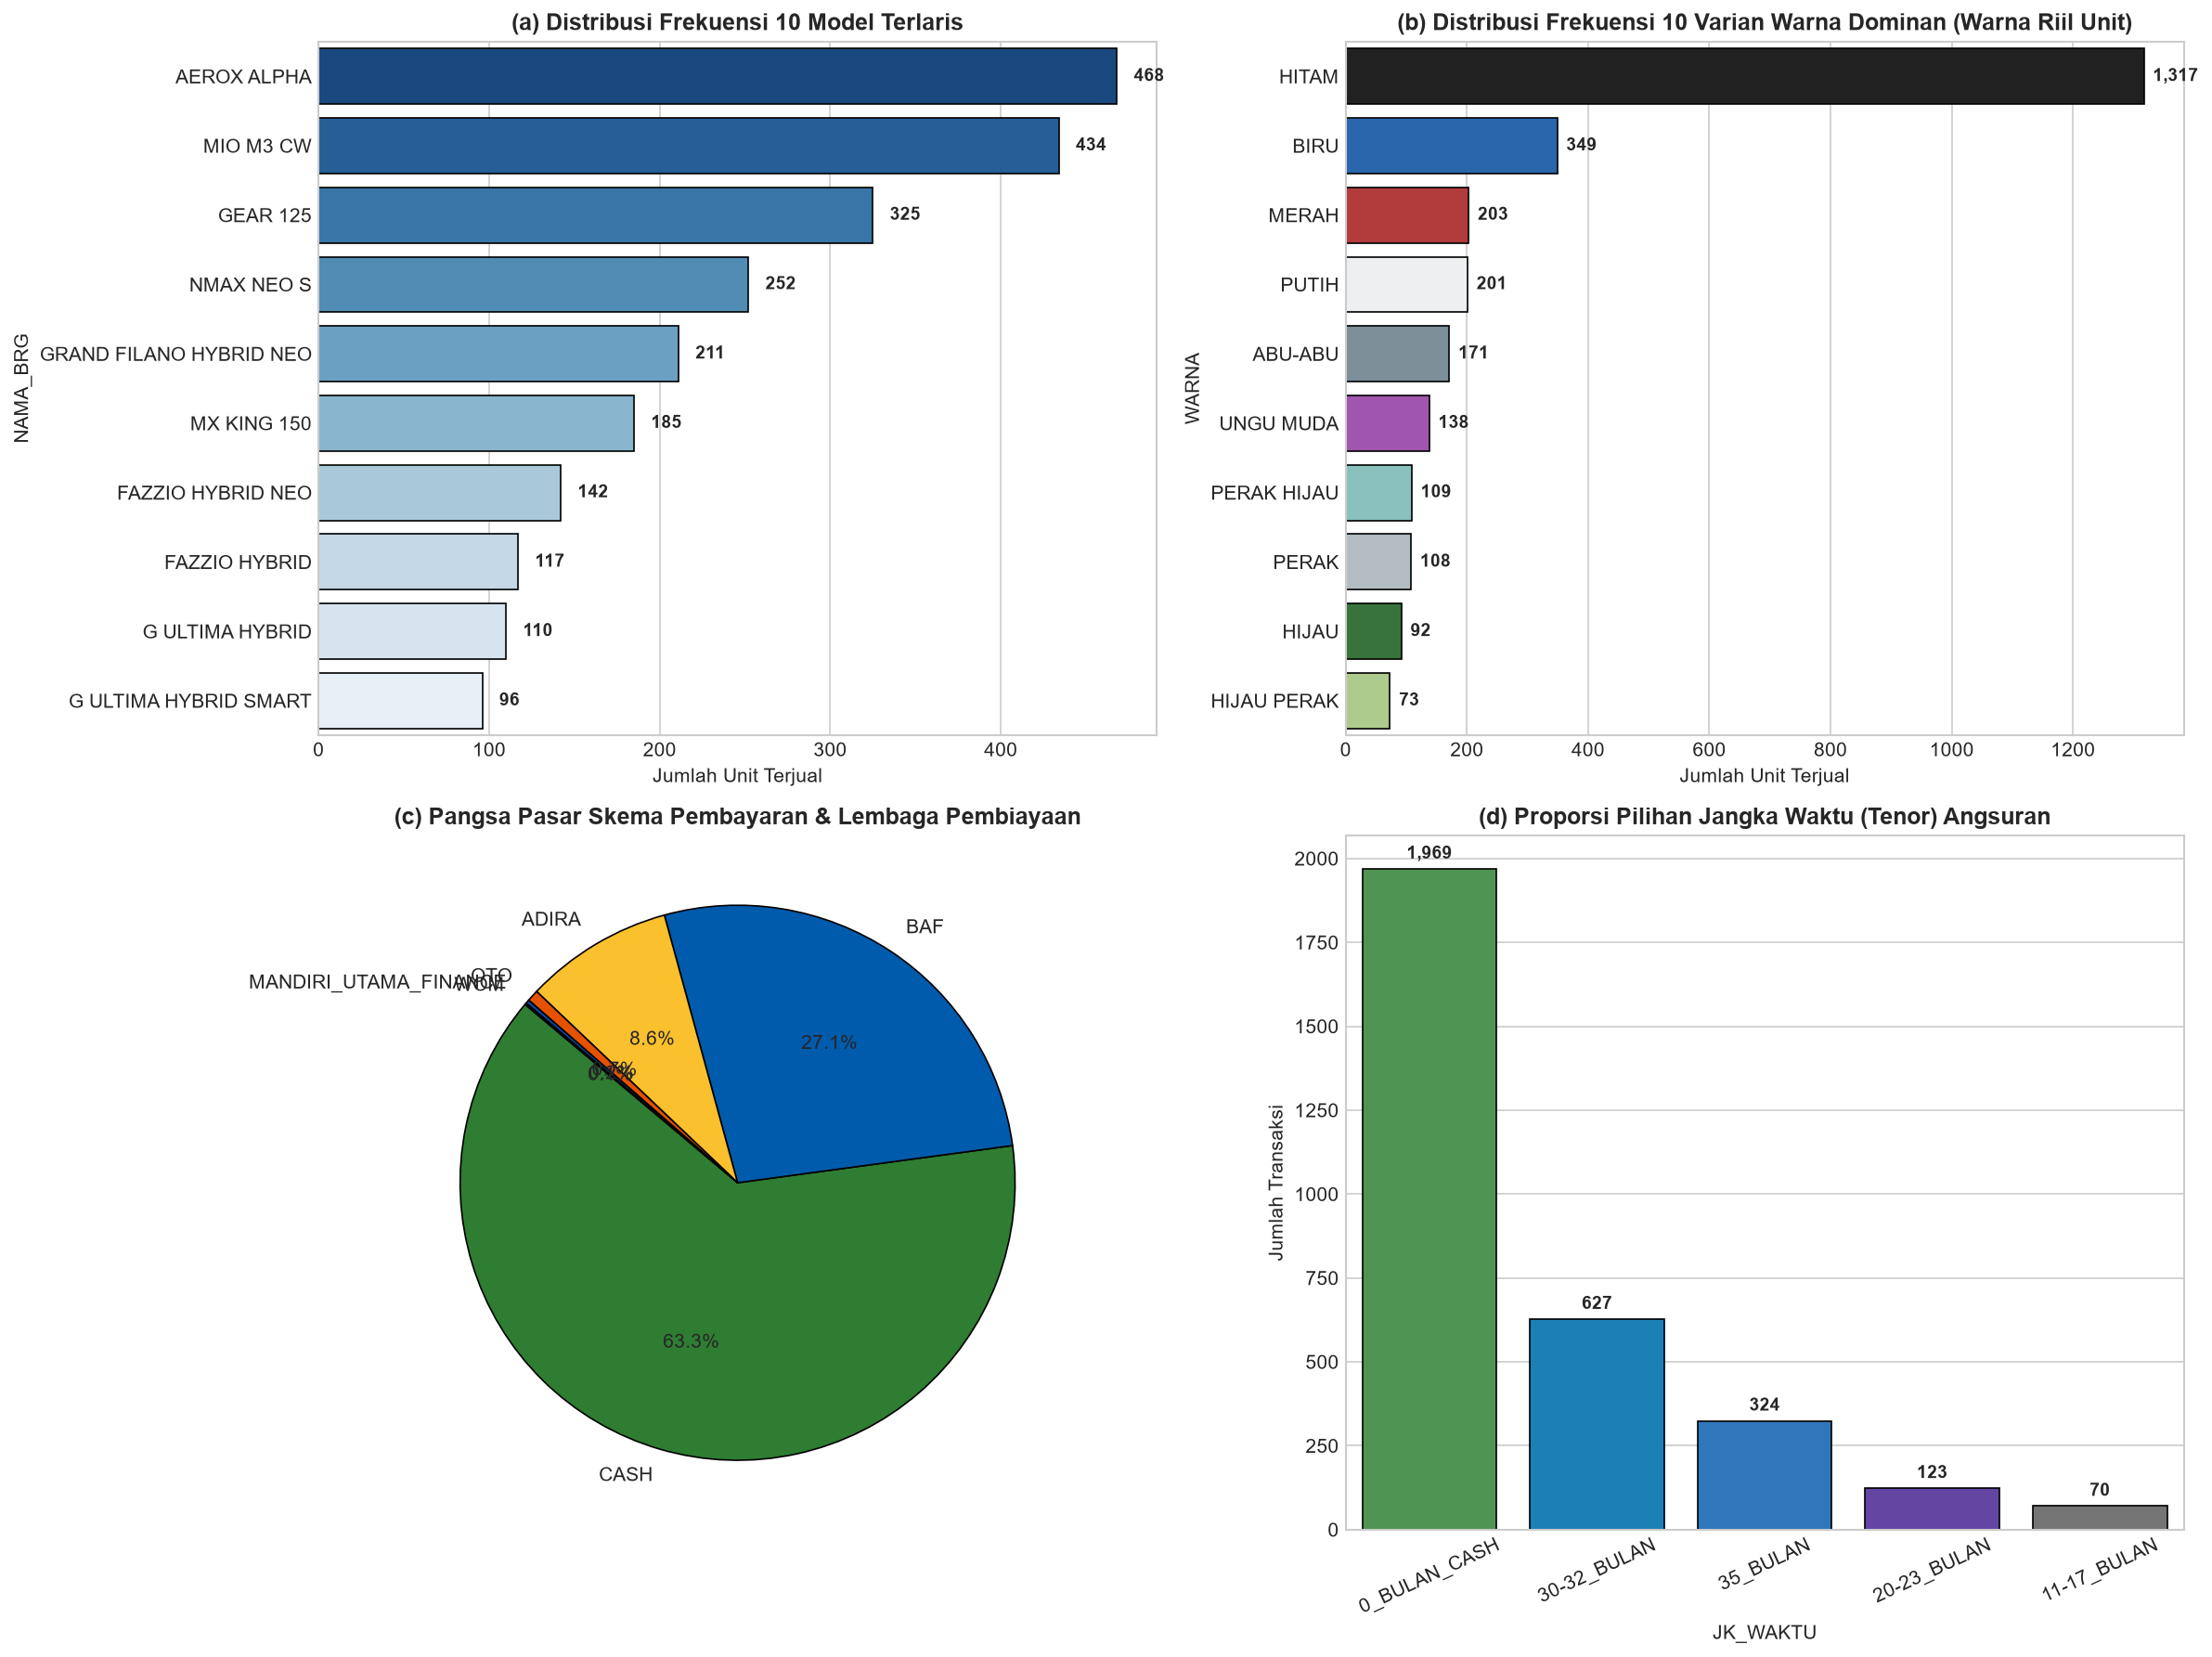

In [4]:
# ==========================================
# VISUALISASI GAMBAR 4.1: DISTRIBUSI FREKUENSI UNIVARIAT 4-IN-1
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# (a) Model Terlaris
sns.barplot(x=s_model.head(10).values, y=s_model.head(10).index, ax=axes[0, 0], palette='Blues_r', edgecolor='black', linewidth=0.8)
axes[0, 0].set_title('(a) Distribusi Frekuensi 10 Model Terlaris', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Jumlah Unit Terjual')
for p in axes[0, 0].patches:
    width = p.get_width()
    axes[0, 0].annotate(f'{int(width):,}', (width + 10, p.get_y() + p.get_height() / 2.),
                        ha='left', va='center', fontsize=9, fontweight='bold')

# (b) Warna Dominan (Warna Riil Unit Sepeda Motor)
warna_palette_univariat = {
    'HITAM': '#212121',
    'BIRU': '#1565C0',
    'MERAH': '#C62828',
    'PUTIH': '#ECEFF1',
    'ABU-ABU': '#78909C',
    'UNGU MUDA': '#AB47BC',
    'PERAK HIJAU': '#80CBC4',
    'PERAK': '#B0BEC5',
    'HIJAU': '#2E7D32',
    'HIJAU PERAK': '#AED581'
}
warna_cols = [warna_palette_univariat.get(w, '#9E9E9E') for w in s_warna.head(10).index]
sns.barplot(x=s_warna.head(10).values, y=s_warna.head(10).index, ax=axes[0, 1], palette=warna_cols, edgecolor='black', linewidth=0.8)
axes[0, 1].set_title('(b) Distribusi Frekuensi 10 Varian Warna Dominan (Warna Riil Unit)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Jumlah Unit Terjual')
for p in axes[0, 1].patches:
    width = p.get_width()
    axes[0, 1].annotate(f'{int(width):,}', (width + 15, p.get_y() + p.get_height() / 2.),
                        ha='left', va='center', fontsize=9, fontweight='bold')

# (c) Skema Pembiayaan (Warna Korporasi Resmi Lembaga Pembiayaan)
lease_palette = {
    'BAF': '#005BAC',                   # Biru BAF (Official Yamaha Finance)
    'CASH': '#2E7D32',                  # Hijau Emerald Pembelian Tunai
    'ADIRA': '#FBC02D',                 # Kuning Adira Finance
    'OTO': '#E65100',                   # Oranye OTO Multiartha
    'MANDIRI_UTAMA_FINANCE': '#0D47A1', # Biru Mandiri Utama Finance
    'WOM': '#6A1B9A',                   # Ungu WOM Finance
    'LAINNYA': '#9E9E9E'                # Abu-abu Netral
}
lease_cols = [lease_palette.get(l, '#9E9E9E') for l in s_lease.index]
axes[1, 0].pie(s_lease.values, labels=s_lease.index, autopct='%1.1f%%', startangle=140, 
               colors=lease_cols, wedgeprops={'edgecolor': 'black', 'linewidth': 0.8})
axes[1, 0].set_title('(c) Pangsa Pasar Skema Pembayaran & Lembaga Pembiayaan', fontsize=12, fontweight='bold')

# (d) Durasi Tenor
tenor_palette = ['#43A047', '#0288D1', '#1976D2', '#5E35B1', '#757575']
sns.barplot(x=s_tenor.index, y=s_tenor.values, ax=axes[1, 1], palette=tenor_palette, edgecolor='black', linewidth=0.8)
axes[1, 1].set_title('(d) Proporsi Pilihan Jangka Waktu (Tenor) Angsuran', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Jumlah Transaksi')
axes[1, 1].tick_params(axis='x', rotation=25)
for p in axes[1, 1].patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        axes[1, 1].annotate(f'{int(height):,}',
                            (p.get_x() + p.get_width() / 2., height + 20),
                            ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('visualisasi_4_1_univariat.png', dpi=300)
plt.show()
print("Grafik 4.1 berhasil disimpan: visualisasi_4_1_univariat.png")


---
## SUB-BAB 4.2: HASIL PRA-PEMROSESAN DAN TRANSFORMASI DATA (DATA PREPARATION) — TUGAS WAHYU
Pembersihan data, standarisasi 5 dimensi, transformasi keranjang predikat multiatribut, dan matriks biner.


In [5]:
# ==========================================
# 4.2.1 PEMBENTUKAN FITUR STANDAR (DF_CLEAN)
# ==========================================
df_clean = pd.DataFrame()
df_clean['NO_FAKTUR'] = df_raw['NO_FAKTUR'].astype(str).str.strip()
df_clean['Model'] = df_raw['NAMA_BRG'].astype(str).str.upper().str.strip()
df_clean['Warna'] = df_raw['WARNA'].astype(str).str.upper().str.strip()
df_clean['Leasing'] = df_raw['NMLEASE'].apply(group_leasing)
df_clean['Tenor'] = df_raw['JK_WAKTU'].apply(group_tenor)
df_clean['Wilayah'] = df_raw['KOTA'].apply(group_kota)

print("5 Sampel Data Transaksi Setelah Standarisasi (df_clean):")
display(df_clean.head())


5 Sampel Data Transaksi Setelah Standarisasi (df_clean):
      NO_FAKTUR              Model  ...         Tenor          Wilayah
0  26FJK0101925      FAZZIO HYBRID  ...   30-32_BULAN    JAKARTA_TIMUR
1  26FJK0101926  ALL NEW AEROX 155  ...   20-23_BULAN    JAKARTA_TIMUR
2  26FJK0101927  FAZZIO HYBRID NEO  ...   20-23_BULAN      KOTA_BEKASI
3  26FJK0101928         FREEGO 125  ...  0_BULAN_CASH  JAKARTA_SELATAN
4  26FJK0101929         FREEGO 125  ...      35_BULAN    JAKARTA_UTARA

[5 rows x 6 columns]


In [6]:
# ==========================================
# 4.2.2 TRANSFORMASI KERANJANG PREDIKAT MULTIATRIBUT
# ==========================================
basket_transactions = []
for _, row in df_clean.iterrows():
    basket_items = [
        f"Model={row['Model']}",
        f"Warna={row['Warna']}",
        f"Leasing={row['Leasing']}",
        f"Tenor={row['Tenor']}",
        f"Wilayah={row['Wilayah']}"
    ]
    basket_transactions.append(basket_items)

print(f"Total Keranjang Transaksi Multiatribut Terbentuk: {len(basket_transactions)}")
print("\n5 Sampel Keranjang Predikat Multiatribut Pertama:")
for idx, b in enumerate(basket_transactions[:5], 1):
    print(f"Faktur {idx} ({df_clean['NO_FAKTUR'].iloc[idx-1]}): {b}")


Total Keranjang Transaksi Multiatribut Terbentuk: 3113

5 Sampel Keranjang Predikat Multiatribut Pertama:
Faktur 1 (26FJK0101925): ['Model=FAZZIO HYBRID', 'Warna=ABU PINK', 'Leasing=BAF', 'Tenor=30-32_BULAN', 'Wilayah=JAKARTA_TIMUR']
Faktur 2 (26FJK0101926): ['Model=ALL NEW AEROX 155', 'Warna=HITAM', 'Leasing=BAF', 'Tenor=20-23_BULAN', 'Wilayah=JAKARTA_TIMUR']
Faktur 3 (26FJK0101927): ['Model=FAZZIO HYBRID NEO', 'Warna=HIJAU MUDA', 'Leasing=ADIRA', 'Tenor=20-23_BULAN', 'Wilayah=KOTA_BEKASI']
Faktur 4 (26FJK0101928): ['Model=FREEGO 125', 'Warna=MERAH', 'Leasing=CASH', 'Tenor=0_BULAN_CASH', 'Wilayah=JAKARTA_SELATAN']
Faktur 5 (26FJK0101929): ['Model=FREEGO 125', 'Warna=MERAH', 'Leasing=BAF', 'Tenor=35_BULAN', 'Wilayah=JAKARTA_UTARA']


In [7]:
# ==========================================
# 4.2.3 PEMBENTUKAN MATRIKS INSIDENSI BINER (ONE-HOT ENCODING)
# ==========================================
te = TransactionEncoder()
te_ary = te.fit(basket_transactions).transform(basket_transactions)
df_binary = pd.DataFrame(te_ary, columns=te.columns_)

print(f"Dimensi Matriks Biner Akhir: {df_binary.shape[0]} Baris x {df_binary.shape[1]} Kolom Predikat")
print("\nCuplikan 5 Baris Pertama Matriks Insidensi Biner (10 Kolom Predikat):")
display(df_binary.iloc[:5, :10].astype(int))


Dimensi Matriks Biner Akhir: 3113 Baris x 89 Kolom Predikat

Cuplikan 5 Baris Pertama Matriks Insidensi Biner (10 Kolom Predikat):
   Leasing=ADIRA  ...  Model=AEROX ALPHA CYBERCITY ABS
0              0  ...                                0
1              0  ...                                0
2              1  ...                                0
3              0  ...                                0
4              0  ...                                0

[5 rows x 10 columns]


---
## SUB-BAB 4.3: HASIL PEMODELAN KOMPUTASI FP-GROWTH (MODELING) — TUGAS MEGI
Pemindaian F-List, konstruksi struktur FP-Tree, dan ekstraksi frequent k-itemset rekursif.


In [8]:
# ==========================================
# 4.3.1 EKSTRAKSI FREQUENT ITEMSETS (FP-GROWTH)
# ==========================================
# Ambang batas Minimum Support = 2% (0.02)
min_sup = 0.02

# Eksekusi algoritma FP-Growth pada matriks biner
frequent_itemsets = fpgrowth(df_binary, min_support=min_sup, use_colnames=True)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))
frequent_itemsets = frequent_itemsets.sort_values(by='support', ascending=False).reset_index(drop=True)

print(f"Total Frequent Itemsets yang Lolos Ambang Batas (Min Support {min_sup*100}%): {len(frequent_itemsets)}")
print("\nDistribusi Panjang Pola Frekuensi Tinggi (k-itemset):")
display(frequent_itemsets['length'].value_counts().sort_index().rename('Jumlah Pola'))

print("\nTop 15 Frequent Itemsets Tertinggi Berdasarkan Support:")
display(frequent_itemsets.head(15))


Total Frequent Itemsets yang Lolos Ambang Batas (Min Support 2.0%): 263

Distribusi Panjang Pola Frekuensi Tinggi (k-itemset):
length
1     39
2    107
3     80
4     32
5      5
Name: Jumlah Pola, dtype: int64

Top 15 Frequent Itemsets Tertinggi Berdasarkan Support:
     support                                           itemsets  length
0   0.632509                    frozenset({Tenor=0_BULAN_CASH})       1
1   0.632509      frozenset({Leasing=CASH, Tenor=0_BULAN_CASH})       2
2   0.632509                          frozenset({Leasing=CASH})       1
3   0.423065                           frozenset({Warna=HITAM})       1
4   0.306778  frozenset({Warna=HITAM, Leasing=CASH, Tenor=0_...       3
5   0.306778             frozenset({Warna=HITAM, Leasing=CASH})       2
6   0.306778       frozenset({Warna=HITAM, Tenor=0_BULAN_CASH})       2
7   0.271121                           frozenset({Leasing=BAF})       1
8   0.201413                     frozenset({Tenor=30-32_BULAN})       1
9   0.175394

---
## SUB-BAB 4.4: HASIL EVALUASI DAN VALIDASI TRI-METRIK KAIDAH ASOSIASI (EVALUATION)
Pembentukan kaidah implikasi asosiasi, seleksi kualitas Tri-Metrik (Support, Confidence, Lift Ratio > 1.0), scatter plot sebaran metrik, dan klasifikasi klaster manajerial.


In [9]:
# ==========================================
# 4.4.1 PEMBENTUKAN KAIDAH ASOSIASI & FILTER TRI-METRIK
# ==========================================
# Ambang batas Minimum Confidence = 50% (0.50)
min_conf = 0.50

# Pembangkitan kaidah asosiasi
raw_rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=min_conf)

# Standar Validasi Tri-Metrik: Hanya pertahankan kaidah dengan Lift Ratio > 1.0 (korelasi positif nyata)
valid_rules = raw_rules[raw_rules['lift'] > 1.0].sort_values(by='lift', ascending=False).reset_index(drop=True)

print(f"Total Kaidah Asosiasi Mentah Terbentuk (Confidence >= {min_conf*100}%): {len(raw_rules)}")
print(f"Total Kaidah Lolos Validasi Ilmiah (Lift Ratio > 1.0)               : {len(valid_rules)}")
print(f"Total Kaidah Gugur / Non-Korelasi (Lift Ratio <= 1.0)              : {len(raw_rules) - len(valid_rules)}")


Total Kaidah Asosiasi Mentah Terbentuk (Confidence >= 50.0%): 401
Total Kaidah Lolos Validasi Ilmiah (Lift Ratio > 1.0)               : 398
Total Kaidah Gugur / Non-Korelasi (Lift Ratio <= 1.0)              : 3


Grafik Evaluasi 4.4 berhasil disimpan: visualisasi_4_4_scatter_rules.png


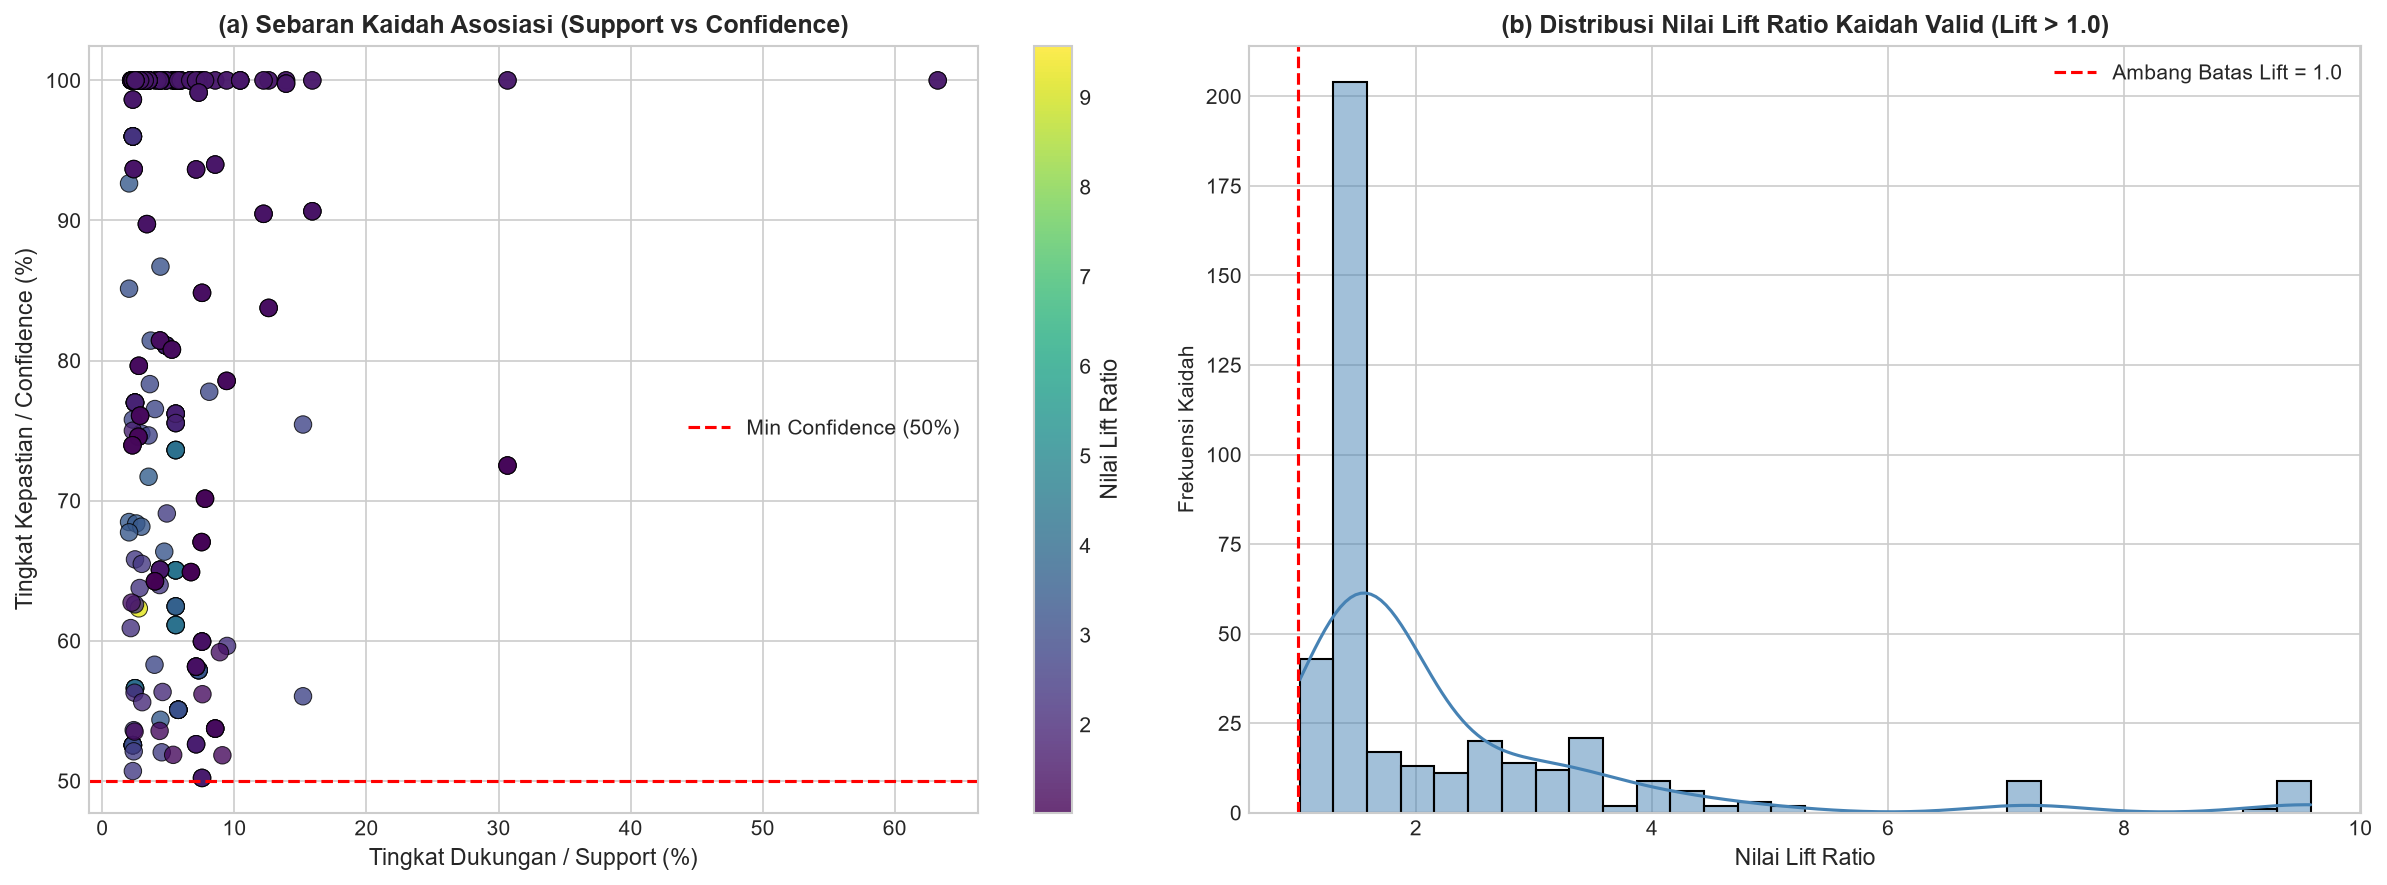

In [10]:
# ==========================================
# 4.4.2 VISUALISASI SEBARAN KAIDAH ASOSIASI & HISTOGRAM LIFT
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# (a) Scatter Plot: Support vs Confidence bergradasi Lift Ratio
scatter = axes[0].scatter(
    valid_rules['support'] * 100, 
    valid_rules['confidence'] * 100, 
    c=valid_rules['lift'], 
    cmap='viridis', 
    s=70, 
    alpha=0.8, 
    edgecolors='black', 
    linewidth=0.5
)
cbar = fig.colorbar(scatter, ax=axes[0])
cbar.set_label('Nilai Lift Ratio', fontsize=11)
axes[0].set_title('(a) Sebaran Kaidah Asosiasi (Support vs Confidence)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tingkat Dukungan / Support (%)', fontsize=11)
axes[0].set_ylabel('Tingkat Kepastian / Confidence (%)', fontsize=11)
axes[0].axhline(y=50, color='r', linestyle='--', label='Min Confidence (50%)')
axes[0].legend()

# (b) Histogram Distribusi Lift Ratio
sns.histplot(valid_rules['lift'], bins=30, kde=True, ax=axes[1], color='steelblue', edgecolor='black')
axes[1].axvline(x=1.0, color='red', linestyle='--', linewidth=1.5, label='Ambang Batas Lift = 1.0')
axes[1].set_title('(b) Distribusi Nilai Lift Ratio Kaidah Valid (Lift > 1.0)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nilai Lift Ratio', fontsize=11)
axes[1].set_ylabel('Frekuensi Kaidah')
axes[1].legend()

plt.tight_layout()
plt.savefig('visualisasi_4_4_scatter_rules.png', dpi=300)
plt.show()
print("Grafik Evaluasi 4.4 berhasil disimpan: visualisasi_4_4_scatter_rules.png")


In [11]:
# ==========================================
# 4.4.3 KATEGORISASI KLASTER MANAJERIAL KAIDAH ASOSIASI
# ==========================================
def classify_rule(row):
    ant = ' '.join(list(row['antecedents']))
    con = ' '.join(list(row['consequents']))
    all_str = ant + ' ' + con
    has_model = 'Model=' in all_str
    has_finance = ('Leasing=' in all_str) or ('Tenor=' in all_str)
    has_warna = 'Warna=' in all_str
    has_wilayah = 'Wilayah=' in all_str
    
    if has_model and has_finance and not has_warna and not has_wilayah:
        return 'Klaster Finansial & Pembiayaan'
    elif has_model and has_warna and not has_finance:
        return 'Klaster Persediaan & Warna'
    elif has_wilayah:
        return 'Klaster Geo-Marketing Spasial'
    elif has_finance and has_warna:
        return 'Klaster Multi-Atribut Kompleks'
    return 'Klaster Umum'

valid_rules['klaster'] = valid_rules.apply(classify_rule, axis=1)

print("Distribusi Jumlah Kaidah Asosiasi Berdasarkan Klaster Manajerial:")
display(valid_rules['klaster'].value_counts().rename('Jumlah Kaidah'))


Distribusi Jumlah Kaidah Asosiasi Berdasarkan Klaster Manajerial:
klaster
Klaster Geo-Marketing Spasial     226
Klaster Multi-Atribut Kompleks    112
Klaster Finansial & Pembiayaan     39
Klaster Persediaan & Warna         14
Klaster Umum                        7
Name: Jumlah Kaidah, dtype: int64


In [12]:
# ==========================================
# 4.4.4 REKAPITULASI TOP 20 KAIDAH ASOSIASI TERKUAT (LIFT TERTINGGI)
# ==========================================
top_20_rules = valid_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift', 'klaster']].head(20).copy()
top_20_rules['Antecedents (X)'] = top_20_rules['antecedents'].apply(lambda x: ', '.join(list(x)))
top_20_rules['Consequents (Y)'] = top_20_rules['consequents'].apply(lambda x: ', '.join(list(x)))
top_20_rules['Support (%)'] = (top_20_rules['support'] * 100).round(2).astype(str) + '%'
top_20_rules['Confidence (%)'] = (top_20_rules['confidence'] * 100).round(2).astype(str) + '%'
top_20_rules['Lift Ratio'] = top_20_rules['lift'].round(3)

display_top_20 = top_20_rules[['Antecedents (X)', 'Consequents (Y)', 'Support (%)', 'Confidence (%)', 'Lift Ratio', 'klaster']]
print("=== TABEL 4.11: TOP 20 KAIDAH ASOSIASI TERKUAT VALIDASI TRI-METRIK ===")
display(display_top_20)

# Ekspor ke file CSV untuk Bab IV
csv_rules_path = 'top_20_association_rules_evaluasi.csv'
display_top_20.to_csv(csv_rules_path, index=False)
print(f"File CSV Kaidah Evaluasi berhasil disimpan di: {csv_rules_path}")


=== TABEL 4.11: TOP 20 KAIDAH ASOSIASI TERKUAT VALIDASI TRI-METRIK ===
                                      Antecedents (X)  ...                         klaster
0                     Leasing=CASH, Warna=HIJAU PERAK  ...  Klaster Multi-Atribut Kompleks
1                                   Warna=HIJAU PERAK  ...  Klaster Multi-Atribut Kompleks
2               Warna=HIJAU PERAK, Tenor=0_BULAN_CASH  ...  Klaster Multi-Atribut Kompleks
3                                   Warna=HIJAU PERAK  ...      Klaster Persediaan & Warna
4               Warna=HIJAU PERAK, Tenor=0_BULAN_CASH  ...  Klaster Multi-Atribut Kompleks
5                                   Warna=HIJAU PERAK  ...  Klaster Multi-Atribut Kompleks
6                     Leasing=CASH, Warna=HIJAU PERAK  ...  Klaster Multi-Atribut Kompleks
7   Leasing=CASH, Warna=HIJAU PERAK, Tenor=0_BULAN...  ...  Klaster Multi-Atribut Kompleks
8                                   Warna=HIJAU PERAK  ...  Klaster Multi-Atribut Kompleks
9                  

---
## SUB-BAB 4.5: INTERPRETASI BISNIS DAN REKOMENDASI MANAJERIAL (DEPLOYMENT)
Penerjemahan kaidah asosiasi ke dalam 3 strategi operasional dealer: Optimasi Persediaan Stok Gudang, Smart Sales Script & Bundling Pembiayaan, serta Geo-Marketing Spasial.


=== TABEL 4.12: MATRIKS SIMULASI REKOMENDASI ALOKASI PENGADAAN PERSEDIAAN GUDANG ===
   Model Sepeda Motor  ...        Status Pengadaan Gudang
0         AEROX ALPHA  ...  Prioritas Utama (Fast-Moving)
1         AEROX ALPHA  ...               Penyeimbang Stok
2         AEROX ALPHA  ...               Penyeimbang Stok
3           MIO M3 CW  ...  Prioritas Utama (Fast-Moving)
4           MIO M3 CW  ...               Penyeimbang Stok
5           MIO M3 CW  ...               Penyeimbang Stok
6            GEAR 125  ...  Prioritas Utama (Fast-Moving)
7            GEAR 125  ...               Penyeimbang Stok
8            GEAR 125  ...               Penyeimbang Stok
9          NMAX NEO S  ...  Prioritas Utama (Fast-Moving)
10         NMAX NEO S  ...  Prioritas Utama (Fast-Moving)
11         NMAX NEO S  ...               Penyeimbang Stok
12      FAZZIO HYBRID  ...  Prioritas Utama (Fast-Moving)
13      FAZZIO HYBRID  ...               Penyeimbang Stok
14      FAZZIO HYBRID  ...               Peny

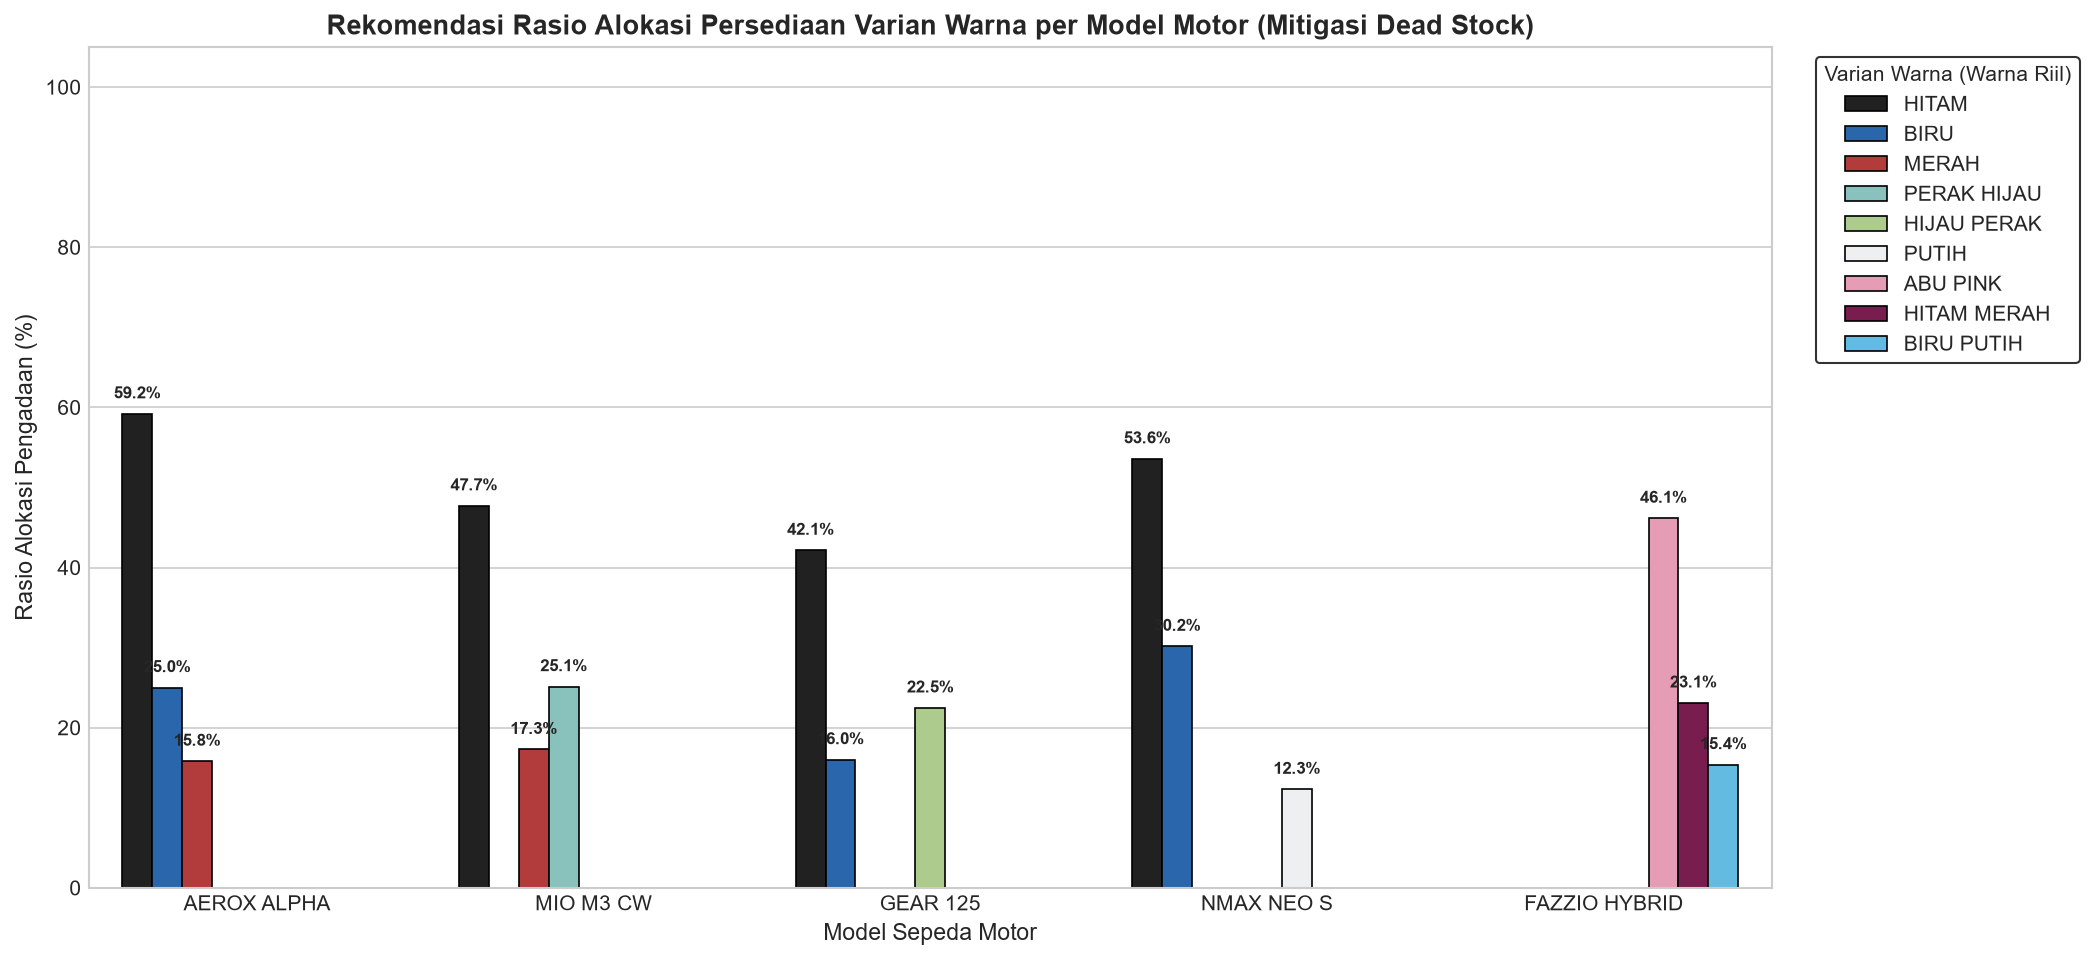

In [13]:
# ==========================================
# 4.5.1 SIMULASI REKOMENDASI MANAJEMEN PERSEDIAAN (INVENTORY ALLOCATION)
# ==========================================
# Ekstraksi probabilitas bersyarat P(Warna | Model) untuk model terlaris
top_models = ['AEROX ALPHA', 'MIO M3 CW', 'GEAR 125', 'NMAX NEO S', 'FAZZIO HYBRID']
inventory_allocation = []

for m in top_models:
    sub = df_clean[df_clean['Model'] == m]
    warna_counts = sub['Warna'].value_counts()
    for w, count in warna_counts.head(3).items():
        ratio = count / len(sub) * 100
        inventory_allocation.append({
            'Model Sepeda Motor': m,
            'Varian Warna': w,
            'Frekuensi Terjual': count,
            'Rasio Alokasi Rekomendasi (%)': round(ratio, 2),
            'Status Pengadaan Gudang': 'Prioritas Utama (Fast-Moving)' if ratio >= 30 else 'Penyeimbang Stok'
        })

df_inventory_rec = pd.DataFrame(inventory_allocation)
print("=== TABEL 4.12: MATRIKS SIMULASI REKOMENDASI ALOKASI PENGADAAN PERSEDIAAN GUDANG ===")
display(df_inventory_rec)

# Visualisasi Alokasi Warna per Model dengan Palet Warna Riil Sepeda Motor
warna_inventory_palette = {
    'HITAM': '#212121',        # Hitam Pekat Glossy / Matte
    'BIRU': '#1565C0',         # Biru Khas Yamaha Racing
    'MERAH': '#C62828',        # Merah Sporty
    'PUTIH': '#ECEFF1',        # Putih Pearl / Mutiara
    'ABU PINK': '#F48FB1',     # Pastel Rose / Abu Pink (Fazzio Hybrid)
    'HITAM MERAH': '#880E4F',  # Varian Two-Tone Hitam Aksen Merah
    'BIRU PUTIH': '#4FC3F7',   # Varian Two-Tone Biru Putih Pastel
    'PERAK HIJAU': '#80CBC4',  # Mint Green / Perak Hijau (Mio M3)
    'HIJAU PERAK': '#AED581'   # Sage Silver / Hijau Perak (Gear 125)
}

plt.figure(figsize=(14, 6.5))
bar_plot = sns.barplot(
    data=df_inventory_rec, 
    x='Model Sepeda Motor', 
    y='Rasio Alokasi Rekomendasi (%)', 
    hue='Varian Warna', 
    palette=warna_inventory_palette, 
    edgecolor='black', 
    linewidth=0.8
)
plt.title('Rekomendasi Rasio Alokasi Persediaan Varian Warna per Model Motor (Mitigasi Dead Stock)', fontsize=13, fontweight='bold')
plt.ylabel('Rasio Alokasi Pengadaan (%)', fontsize=11)
plt.xlabel('Model Sepeda Motor', fontsize=11)
plt.ylim(0, 105)

# Menambahkan label persentase di atas setiap batang
for p in bar_plot.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        bar_plot.annotate(f'{height:.1f}%',
                          (p.get_x() + p.get_width() / 2., height + 1.5),
                          ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.legend(title='Varian Warna (Warna Riil)', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, edgecolor='black')
plt.tight_layout()
plt.savefig('visualisasi_4_5_alokasi_persediaan.png', dpi=300)
plt.show()
print("Grafik Persediaan 4.5 berhasil disimpan: visualisasi_4_5_alokasi_persediaan.png")


In [14]:
# ==========================================
# 4.5.2 SIMULASI STRATEGI PENJUALAN TERPADU (SMART SALES SCRIPT MATRIX)
# ==========================================
# Menghubungkan Model Terlaris dengan Preferensi Pembiayaan Tertinggi
sales_script_data = []

for m in top_models:
    sub = df_clean[df_clean['Model'] == m]
    top_lease = sub['Leasing'].value_counts().index[0]
    top_lease_pct = (sub['Leasing'].value_counts().iloc[0] / len(sub)) * 100
    
    # Ambil tenor terpopuler jika kredit, atau cash
    sub_credit = sub[sub['Leasing'] != 'CASH']
    if len(sub_credit) > 0:
        top_tenor = sub_credit['Tenor'].value_counts().index[0]
        top_tenor_pct = (sub_credit['Tenor'].value_counts().iloc[0] / len(sub_credit)) * 100
    else:
        top_tenor = '0_BULAN_CASH'
        top_tenor_pct = 100.0
        
    sales_script_data.append({
        'Model Diminati Konsumen': m,
        'Skema / Leasing Utama': f"{top_lease} ({top_lease_pct:.1f}%)",
        'Rekomendasi Tenor Cicilan': f"{top_tenor} ({top_tenor_pct:.1f}% kredit)",
        'Rekomendasi Bundling / Action Script': f"Tawarkan promo uang muka rendah BAF tenor 30-35 bulan & bonus aksesoris resmi." if top_lease == 'BAF' else "Berikan opsi diskon tunai langsung atau asuransi gratis."
    })

df_sales_script = pd.DataFrame(sales_script_data)
print("=== TABEL 4.13: SMART SALES SCRIPT & PROMOTIONAL BUNDLING MATRIX ===")
display(df_sales_script)
df_sales_script.to_csv('matriks_smart_sales_script.csv', index=False)


=== TABEL 4.13: SMART SALES SCRIPT & PROMOTIONAL BUNDLING MATRIX ===
  Model Diminati Konsumen  ...               Rekomendasi Bundling / Action Script
0             AEROX ALPHA  ...  Berikan opsi diskon tunai langsung atau asuran...
1               MIO M3 CW  ...  Berikan opsi diskon tunai langsung atau asuran...
2                GEAR 125  ...  Berikan opsi diskon tunai langsung atau asuran...
3              NMAX NEO S  ...  Tawarkan promo uang muka rendah BAF tenor 30-3...
4           FAZZIO HYBRID  ...  Tawarkan promo uang muka rendah BAF tenor 30-3...

[5 rows x 4 columns]


=== TABEL 4.14: MATRIKS DISTRIBUSI MODEL BERBASIS KAWASAN KONSUMEN (GEO-MARKETING %) ===
Region_Cluster  Kawasan Bekasi Raya  ...  Kawasan Tangerang
Model                                ...                   
AEROX ALPHA                    5.98  ...              11.32
MIO M3 CW                     28.34  ...               0.00
GEAR 125                       0.31  ...               0.00
NMAX NEO S                    42.86  ...               5.16
FAZZIO HYBRID                 31.62  ...               7.69

[5 rows x 4 columns]
Grafik Geo-Marketing 4.5 berhasil disimpan: visualisasi_4_5_geo_marketing.png


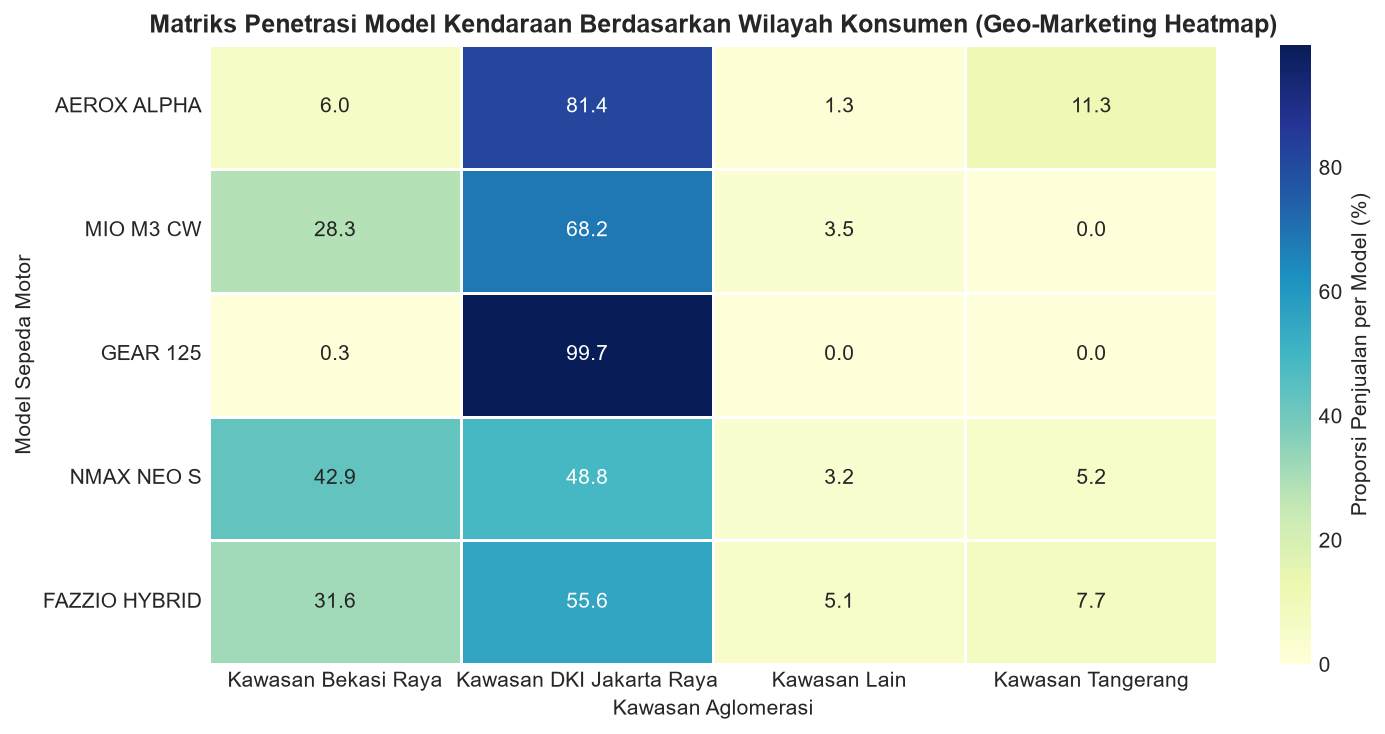

In [15]:
# ==========================================
# 4.5.3 SIMULASI STRATEGI PEMASARAN SPASIAL (GEO-MARKETING STRATEGY)
# ==========================================
# Proporsi Penjualan Model Terlaris di 2 Koridor Utama: Bekasi Raya vs DKI Jakarta Raya
def simplify_region(kota):
    if 'BEKASI' in kota: return 'Kawasan Bekasi Raya'
    elif 'JAKARTA' in kota: return 'Kawasan DKI Jakarta Raya'
    elif 'TANGERANG' in kota: return 'Kawasan Tangerang'
    return 'Kawasan Lain'

df_clean['Region_Cluster'] = df_clean['Wilayah'].apply(simplify_region)

geo_matrix = pd.crosstab(df_clean['Model'], df_clean['Region_Cluster'], normalize='index') * 100
geo_matrix_top = geo_matrix.loc[top_models].round(2)

print("=== TABEL 4.14: MATRIKS DISTRIBUSI MODEL BERBASIS KAWASAN KONSUMEN (GEO-MARKETING %) ===")
display(geo_matrix_top)

# Visualisasi Heatmap Geo-Marketing
plt.figure(figsize=(10, 5))
sns.heatmap(geo_matrix_top, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': 'Proporsi Penjualan per Model (%)'}, linewidths=0.5)
plt.title('Matriks Penetrasi Model Kendaraan Berdasarkan Wilayah Konsumen (Geo-Marketing Heatmap)', fontsize=12, fontweight='bold')
plt.xlabel('Kawasan Aglomerasi')
plt.ylabel('Model Sepeda Motor')
plt.tight_layout()
plt.savefig('visualisasi_4_5_geo_marketing.png', dpi=300)
plt.show()
print("Grafik Geo-Marketing 4.5 berhasil disimpan: visualisasi_4_5_geo_marketing.png")


In [16]:
# ==========================================
# 4.5.4 RINGKASAN HILIRISASI BISNIS PRESKRIPTIF DEALER
# ==========================================
roadmap_data = [
    {
        'Pilar Strategis': 'Manajemen Persediaan (Inventory)',
        'Temuan Kaidah Asosiasi': 'Warna Hitam menyerap >40% unit; Varian Perak/Pastel terikat eksklusif ke Gear/Classy.',
        'Aksi Preskriptif Manajerial': 'Terapkan rasio alokasi stok 4:2:1 (Hitam : Biru : Warna Khusus) di Gudang Bekasi untuk menekan dead stock.'
    },
    {
        'Pilar Strategis': 'Skema Pembiayaan (Financing)',
        'Temuan Kaidah Asosiasi': 'Konsumen kredit terikat kuat ke BAF (73,8%) dengan tenor 30-35 bulan (83,1%).',
        'Aksi Preskriptif Manajerial': 'Kembangkan program joint-promosi DP fleksibel bersama BAF dengan target cicilan terjangkau.'
    },
    {
        'Pilar Strategis': 'Pemasaran Wilayah (Geo-Marketing)',
        'Temuan Kaidah Asosiasi': '64,6% pembeli berdomisili di DKI Jakarta meski dealer berlokasi di Bekasi.',
        'Aksi Preskriptif Manajerial': 'Fasilitasi layanan digital delivery unit & pengurusan berkas STNK lintas wilayah secara kilat.'
    }
]

df_roadmap = pd.DataFrame(roadmap_data)
print("=== TABEL 4.15: PETA JALAN STRATEGIS HILIRISASI BISNIS PRESKRIPTIF DEALER PT. SSM MOTOR ===")
display(df_roadmap)
df_roadmap.to_csv('matriks_hilirisasi_bisnis_roadmap.csv', index=False)
print("\nSeluruh proses komputasi CRISP-DM (Sub-bab 4.1 s.d. 4.5) telah berhasil diselesaikan!")


=== TABEL 4.15: PETA JALAN STRATEGIS HILIRISASI BISNIS PRESKRIPTIF DEALER PT. SSM MOTOR ===
                     Pilar Strategis  ...                        Aksi Preskriptif Manajerial
0   Manajemen Persediaan (Inventory)  ...  Terapkan rasio alokasi stok 4:2:1 (Hitam : Bir...
1       Skema Pembiayaan (Financing)  ...  Kembangkan program joint-promosi DP fleksibel ...
2  Pemasaran Wilayah (Geo-Marketing)  ...  Fasilitasi layanan digital delivery unit & pen...

[3 rows x 3 columns]

Seluruh proses komputasi CRISP-DM (Sub-bab 4.1 s.d. 4.5) telah berhasil diselesaikan!
